# 4. Vectors and Matrices: Exercise

Name: Xiuning

$$ % Latex macros
\newcommand{\mat}[1]{\begin{pmatrix} #1 \end{pmatrix}}
\newcommand{\p}[2]{\frac{\partial #1}{\partial #2}}
\newcommand{\b}[1]{\boldsymbol{#1}}
\newcommand{\w}{\boldsymbol{w}}
\newcommand{\x}{\boldsymbol{x}}
\newcommand{\y}{\boldsymbol{y}}
$$

In [12]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1) Determinant and eigenvalues
1) For a 2x2 matrix
$A = \left(\begin{array}{cc} a & b\\ c & d \end{array}\right)$,
let us verify that $\det A = ad - bc$ in the case graphically shown below ($a, b, c, d$ are positive).

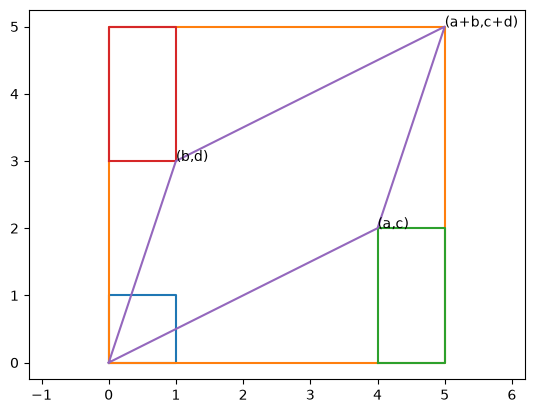

In [2]:
A = np.array([[4, 1], [2, 3]])
plt.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0])
plt.plot([0, A[0,0]+A[0,1], A[0,0]+A[0,1], 0, 0],
         [0, 0, A[1,0]+A[1,1], A[1,0]+A[1,1], 0])
plt.plot([A[0,0], A[0,0]+A[0,1], A[0,0]+A[0,1], A[0,0], A[0,0]],
         [0, 0, A[1,0], A[1,0], 0])
plt.plot([0, A[0,1], A[0,1], 0, 0],
         [A[1,1], A[1,1], A[1,0]+A[1,1], A[1,0]+A[1,1], A[1,1]])
plt.plot([0, A[0,0], A[0,0]+A[0,1], A[0,1], 0],
         [0, A[1,0], A[1,0]+A[1,1], A[1,1], 0])
plt.axis('equal')
plt.text(A[0,0], A[1,0], '(a,c)')
plt.text(A[0,1], A[1,1], '(b,d)')
plt.text(A[0,0]+A[0,1], A[1,0]+A[1,1], '(a+b,c+d)');

A unit square is transformed into a parallelogram. Its area $S$ can be derived as follows:  
Large rectangle: $ S_1 = (a+b)(c+d) $  
Small rectangle: $ S_2 = b*c $  
Bottom/top triangle: $ S_3 = a*c/2 $  
Left/right triangle: $ S_4 = b*d/2 $  
Parallelogram: $ S = S_1 - 2*S_2 - 2*S_3 - 2*S_4 = ad-bc $  

2) The determinant equals the product of all eigenvalues. Verify this numerically for multiple cases and explain intuitively why that should hold.

In [ ]:
# A = np.array([[1, 2], [3, 4]])
A = np.random.rand(2, 2)
# A = np.random.rand(3, 3)
det = np.linalg.det(A)
print('detA = ', det)
lam, V = np.linalg.eig(A)
print(np.prod(lam))

detA =  0.30807851830132904
(0.308078518301329-0j)


The determinant represents area change

The eigenvalues mean the change on eigenvector directions

Therefore, the determinant equals the product of all eigenvalues.

## 2) Eigenvalues and matrix product
1) Make a random (or hand-designed) $m\times m$ matrix $A$. Compute its eigenvalues and eigenvectors. From a random (or your preferred) initial point $\b{x}$, compute $A\b{x}, A^2\b{x}, A^3\b{x},...$ and visualize the points. Then characterize the behavior of the points with respect the eigenvalues and eigenvectors.

A =  [[ 0.12501117 -0.37224225 -0.51744371]
 [ 2.83359223  0.7716107  -2.47680836]
 [-2.74514259 -0.38341595  0.02936926]]
lam =  [ 1.18044222+0.89534613j  1.18044222-0.89534613j -1.4348933 +0.j        ]
x =  [-0.74125162  0.40110888  0.89276059]


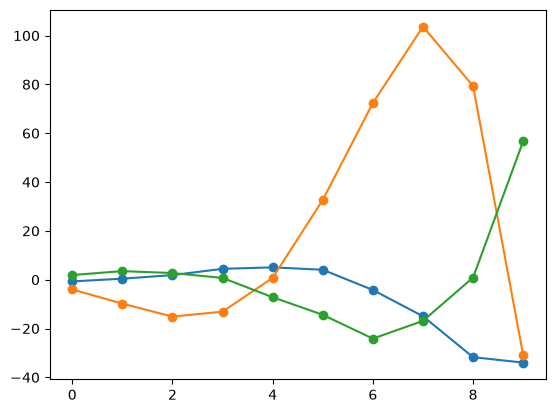

In [2]:
m = 3
A = np.random.uniform(-3, 3, (m, m)) 
print('A = ', A)
lam, V = np.linalg.eig(A)
print('lam = ', lam)

x = np.random.uniform(-1, 1, m)
print('x = ', x)
n = 10
y = np.zeros((n, m))
y_lam = np.zeros((n, m))
for i in range(10):
    x = A @ x
    y[i] = x.copy()

plt.plot(y, 'o-');

2) Do the above with several different matrices

A =  [[-2.87420686  1.07259854  2.9713885 ]
 [-0.26697719  0.57339806  1.34432202]
 [-2.90133835 -1.0908554   0.22866861]]
lam =  [-0.84396979+2.61511832j -0.84396979-2.61511832j -0.38420061+0.j        ]


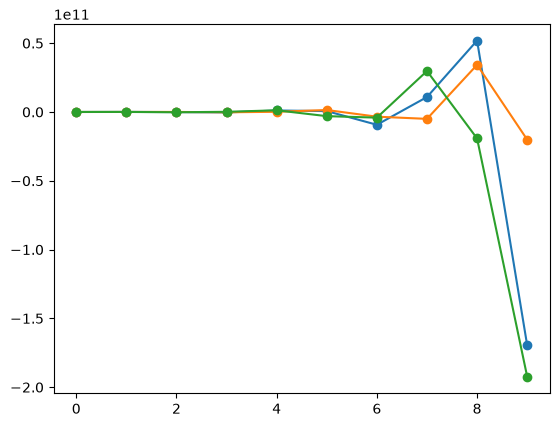

In [4]:
m = 3
A = np.random.uniform(-3, 3, (m, m)) 
print('A = ', A)
lam, V = np.linalg.eig(A)
print('lam = ', lam)


y = np.zeros((n, m))
y_lam = np.zeros((n, m))
for i in range(10):
    x = A @ x
    y[i] = x.copy()

plt.plot(y, 'o-');

## 3) Principal component analysis
Read in the "digits" dataset, originally from `sklearn`.

In [42]:
#data = np.loadtxt("data/digits_data.txt")
#target = np.loadtxt("data/digits_target.txt", dtype='int64')
from sklearn import datasets
digits = datasets.load_digits()
data = digits.data
target = digits.target
data.shape

(1797, 64)

In [47]:
np.savetxt("data/digits_data.txt", data, fmt='%d')
np.savetxt("data/digits_target.txt", target, fmt='%d')

The first ten samples look like these:

In [2]:
data = np.loadtxt("data/digits_data.txt")
target = np.loadtxt("data/digits_target.txt", dtype='int64')

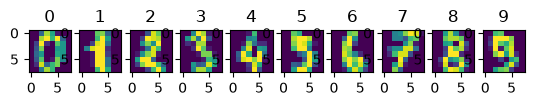

In [46]:
for i in range(10):
    plt.subplot(1,10,i+1)
    plt.imshow(data[i].reshape((8,8)))
    plt.title(target[i])

1) Compute the principal component vectors from all the digits and plot the eigenvalues from the largest to smallest.

In [99]:
C

array([[    0.        ,     0.        ,     0.        , ...,
            0.        ,     0.        ,     0.        ],
       [    0.        ,   739.05175292,  2156.09348915, ...,
         -143.58597663,    88.46577629,   -66.50751252],
       [    0.        ,  2156.09348915, 20302.31942126, ...,
        -1037.58542014,  1268.008069  ,   655.43266555],
       ...,
       [    0.        ,  -143.58597663, -1037.58542014, ...,
        31265.97885365, 14052.39287702,  2582.27323317],
       [    0.        ,    88.46577629,  1268.008069  , ...,
        14052.39287702, 15025.85865331,  4239.26572065],
       [    0.        ,   -66.50751252,   655.43266555, ...,
         2582.27323317,  4239.26572065,  3107.12743461]], shape=(64, 64))

In [9]:
Xm = np.mean(data, axis=0)
X = data - Xm
C = X.T @ X / (X.shape[0] - 1)
lam, V = np.linalg.eigh(C)
ind = np.argsort(-lam)
l = lam[ind]
V = V[:, ind]
print('lam = ', l)
print('V = ', V)
plt.plot(lam, 'o-');

lam =  [ 1.79006930e+02  1.63717747e+02  1.41788439e+02  1.01100375e+02
  6.95131656e+01  5.91085249e+01  5.18845391e+01  4.40151067e+01
  4.03109953e+01  3.70117984e+01  2.85190412e+01  2.73211698e+01
  2.19014881e+01  2.13243565e+01  1.76367222e+01  1.69468639e+01
  1.58513899e+01  1.50044602e+01  1.22344732e+01  1.08868593e+01
  1.06935663e+01  9.58259779e+00  9.22640260e+00  8.69036872e+00
  8.36561190e+00  7.16577961e+00  6.91973881e+00  6.19295508e+00
  5.88499123e+00  5.15586690e+00  4.49129656e+00  4.24687799e+00
  4.04743883e+00  3.94340334e+00  3.70647245e+00  3.53165306e+00
  3.08457409e+00  2.73780002e+00  2.67210896e+00  2.54170563e+00
  2.28298744e+00  1.90724229e+00  1.81716569e+00  1.68996439e+00
  1.40197220e+00  1.29221888e+00  1.15893419e+00  9.31220008e-01
  6.69850594e-01  4.86065217e-01  2.52350432e-01  9.91527944e-02
  6.31307848e-02  6.07377581e-02  3.96662297e-02  1.49505636e-02
  8.47307261e-03  3.62365957e-03  1.27705113e-03  6.61270906e-04
  4.12223305e-04  

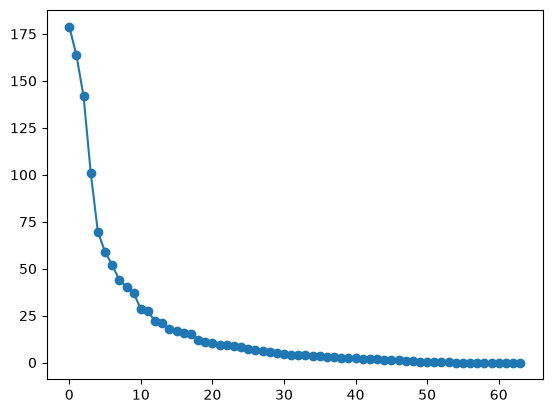

In [10]:
U, S, Vt = np.linalg.svd(X, full_matrices=False)
L = S**2 / X.shape[0]
plt.plot(L, 'o-');

2) Visualize the principal vectors as images.

In [82]:
V

array([[ 0.        +0.j,  0.        +0.j,  1.        +0.j, ...,
         0.        +0.j,  0.        +0.j,  0.        +0.j],
       [ 0.        +0.j,  0.        +0.j,  0.        +0.j, ...,
        -0.01834207+0.j,  0.01010646+0.j,  0.01730947+0.j],
       [ 0.        +0.j,  0.        +0.j,  0.        +0.j, ...,
        -0.12647554+0.j,  0.04908492+0.j,  0.22342883+0.j],
       ...,
       [ 0.        +0.j,  0.        +0.j,  0.        +0.j, ...,
        -0.23208416+0.j, -0.17669712+0.j,  0.08941847+0.j],
       [ 0.        +0.j,  0.        +0.j,  0.        +0.j, ...,
        -0.16702656+0.j, -0.01945471+0.j,  0.03659771+0.j],
       [ 0.        +0.j,  0.        +0.j,  0.        +0.j, ...,
        -0.03480438+0.j,  0.00669694+0.j,  0.0114685 +0.j]],
      shape=(64, 64))

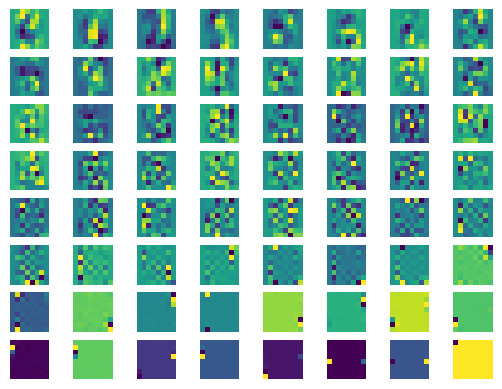

In [20]:
for i in range(len(V)):
    plt.subplot(8,8,i+1)
    plt.imshow(Vt[i].reshape((8,8)))
    # plt.imshow(V[:,i].reshape((8,8)))
    plt.axis('off')

3) Scatterplot the digits in the first two or three principal component space, with different colors/markers for digits.

(np.float64(-34.3134055971412),
 np.float64(34.84362679999173),
 np.float64(-32.97153772239361),
 np.float64(30.373780179556643))

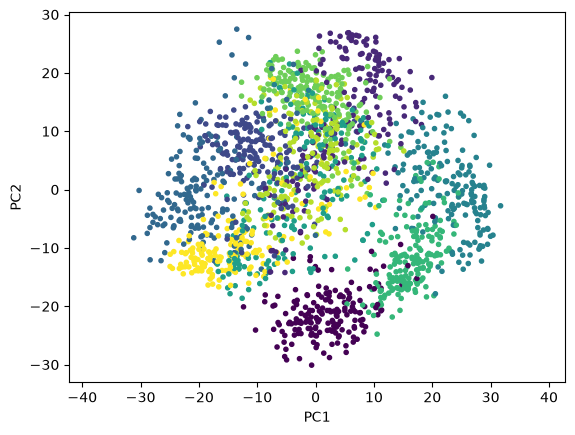

In [14]:
Z = X @ V
plt.scatter(Z[:,0], Z[:,1], c=target, marker='.')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.axis('equal')

4) Take a sample digit, decompose it into principal components, and reconstruct the digit from the first $m$ components. See how the quality of reproduction depends on $m$.

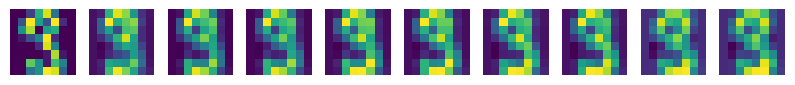

In [17]:
K = 10
i = np.random.randint(data.shape[0])
plt.figure(figsize=(10, 4))
plt.subplot(1, K, 1)
plt.imshow(data[i].reshape((8, 8)))
plt.axis('off')
for k in range(1, K):    
    Xrec = Xm + V[:, :k] @ Z[i, :k]
    plt.subplot(1, K, k+1)
    plt.imshow(Xrec.reshape((8, 8)))
    plt.axis('off')